In [12]:
import os
import tensorflow as tf

# Dataset paths
TRAIN_DIR = r"D:\Brain Tumor\Dataset\Training"
TEST_DIR = r"D:\Brain Tumor\Dataset\Testing"

# Check dataset paths
print(f"Training Directory: {TRAIN_DIR}")
print(f"Training Directory Exists: {os.path.exists(TRAIN_DIR)}")

print(f"Testing Directory: {TEST_DIR}")
print(f"Testing Directory Exists: {os.path.exists(TEST_DIR)}")

if not os.path.exists(TRAIN_DIR):
    raise FileNotFoundError(f"Training directory not found: {TRAIN_DIR}")

if not os.path.exists(TEST_DIR):
    raise FileNotFoundError(f"Testing directory not found: {TEST_DIR}")

# Image settings
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=123
)

# Load testing dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=123
)

# Get class names
class_names = train_ds.class_names

print(f"\nLoaded {len(class_names)} classes: {class_names}")

Training Directory: D:\Brain Tumor\Dataset\Training
Training Directory Exists: True
Testing Directory: D:\Brain Tumor\Dataset\Testing
Testing Directory Exists: True
Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.

Loaded 4 classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


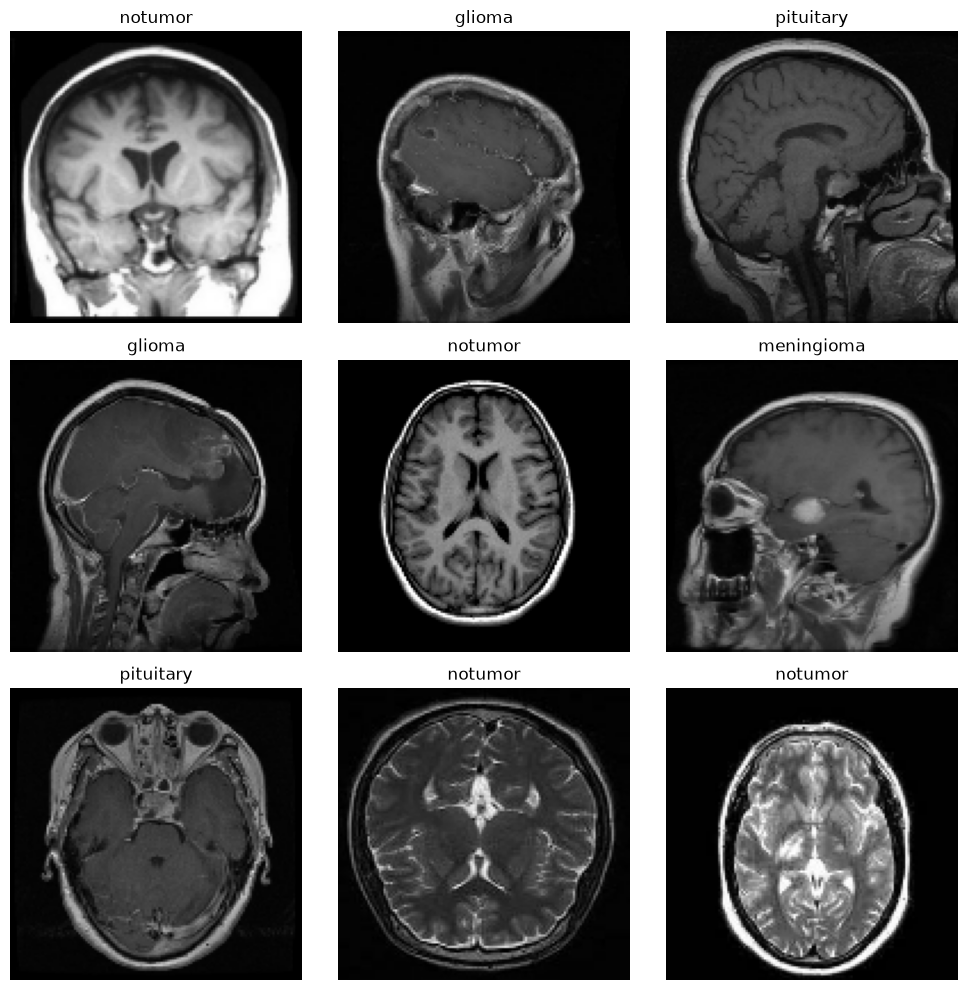

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

model.summary()

d:\Brain Tumor\.venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Custom callback to print cleanly rounded accuracy and loss every epoch
class RoundMetricsCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        train_acc = round(logs.get('accuracy', 0) * 100, 2)
        val_acc = round(logs.get('val_accuracy', 0) * 100, 2)
        train_loss = round(logs.get('loss', 0), 4)
        val_loss = round(logs.get('val_loss', 0), 4)
        print(f" -> Epoch {epoch + 1}: Train Acc = {train_acc}% | Val Acc = {val_acc}% | Train Loss = {train_loss} | Val Loss = {val_loss}")

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=2,
    callbacks=[RoundMetricsCallback()]
)

Epoch 1/10


d:\Brain Tumor\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 -> Epoch 1: Train Acc = 73.11% | Val Acc = 73.12% | Train Loss = 0.6536 | Val Loss = 0.8917
175/175 - 38s - 220ms/step - accuracy: 0.7311 - loss: 0.6536 - val_accuracy: 0.7312 - val_loss: 0.8917
Epoch 2/10
 -> Epoch 2: Train Acc = 87.98% | Val Acc = 80.94% | Train Loss = 0.324 | Val Loss = 0.8139
175/175 - 36s - 206ms/step - accuracy: 0.8798 - loss: 0.3240 - val_accuracy: 0.8094 - val_loss: 0.8139
Epoch 3/10
 -> Epoch 3: Train Acc = 92.7% | Val Acc = 83.75% | Train Loss = 0.1964 | Val Loss = 0.8265
175/175 - 32s - 182ms/step - accuracy: 0.9270 - loss: 0.1964 - val_accuracy: 0.8375 - val_loss: 0.8265
Epoch 4/10
 -> Epoch 4: Train Acc = 96.48% | Val Acc = 86.12% | Train Loss = 0.1014 | Val Loss = 1.0755
175/175 - 39s - 223ms/step - accuracy: 0.9648 - loss: 0.1014 - val_accuracy: 0.8612 - val_loss: 1.0755
Epoch 5/10
 -> Epoch 5: Train Acc = 97.21% | Val Acc = 86.81% | Train Loss = 0.0713 | Val Loss = 0.9816
175/175 - 35s - 199ms/step - accuracy: 0.9721 - loss: 0.0713 - val_accuracy: 0.86


--- Epoch Summary ---
Epoch 1: Train Accuracy = 73.11% | Val Accuracy = 73.12%
Epoch 2: Train Accuracy = 87.98% | Val Accuracy = 80.94%
Epoch 3: Train Accuracy = 92.7% | Val Accuracy = 83.75%
Epoch 4: Train Accuracy = 96.48% | Val Accuracy = 86.12%
Epoch 5: Train Accuracy = 97.21% | Val Accuracy = 86.81%
Epoch 6: Train Accuracy = 98.64% | Val Accuracy = 89.06%
Epoch 7: Train Accuracy = 99.3% | Val Accuracy = 86.94%
Epoch 8: Train Accuracy = 99.07% | Val Accuracy = 88.0%
Epoch 9: Train Accuracy = 99.37% | Val Accuracy = 89.19%
Epoch 10: Train Accuracy = 99.05% | Val Accuracy = 88.94%

Final Validation Accuracy: 88.94%
Final Validation Loss:     1.0948


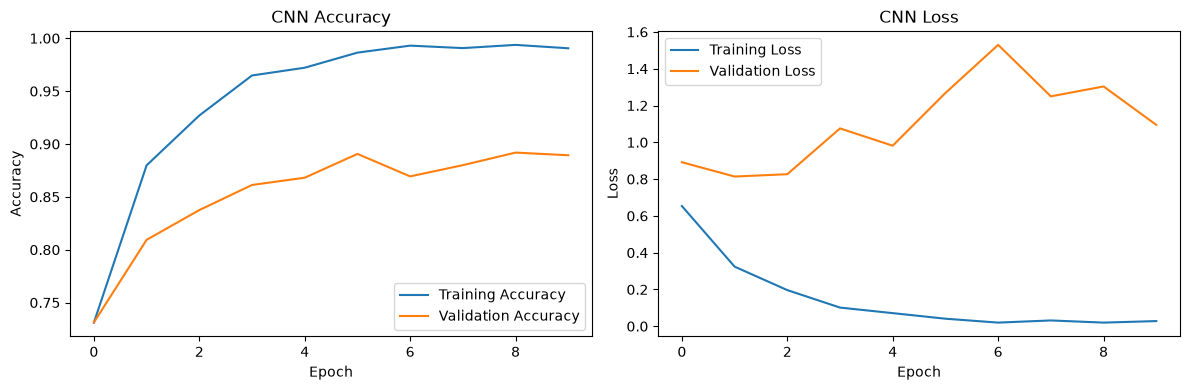

In [11]:
# Epoch-by-epoch rounded summary
print("\n--- Epoch Summary ---")
for i, (train_acc, val_acc) in enumerate(zip(history.history['accuracy'], history.history['val_accuracy']), start=1):
    print(f"Epoch {i}: Train Accuracy = {round(train_acc * 100, 2)}% | Val Accuracy = {round(val_acc * 100, 2)}%")

# Final evaluation
loss, accuracy = model.evaluate(val_ds, verbose=0)
print(f"\nFinal Validation Accuracy: {round(accuracy * 100, 2)}%")
print(f"Final Validation Loss:     {round(loss, 4)}")

# Plot metrics
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Loss')
plt.legend()

plt.tight_layout()
plt.show()